# SSH Model Phase Transition Detection: Visualization

This notebook loads pre-computed results from the `ssh_ml_phase` package and creates
all comparison plots. Run each method separately first:

```bash
python -m ssh_ml_phase.pca_method
python -m ssh_ml_phase.umap_method
python -m ssh_ml_phase.assaad_method
python -m ssh_ml_phase.autoencoder
```

Or run a single alpha for fast iteration:
```bash
python -m ssh_ml_phase.pca_method --alphas 0.240
```

**FSS reference values (w=0.5):**

| $\alpha$ | $T_c$ | $\beta_c$ |
|----------|-------|----------|
| 0.240    | 0.057 | 17.5     |
| 0.245    | 0.070 | 14.3     |
| 0.250    | 0.080 | 12.5     |
| 0.255    | 0.081 | 12.3     |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os

plt.rcParams.update({
    'font.size': 12,
    'figure.figsize': (10, 6),
    'mathtext.fontset': 'cm',
})

from ssh_ml_phase.config import ALPHAS, FSS_ALPHA, FSS_BETA_C, RESULTS_DIR # type: ignore

def load_npz(name):
    path = os.path.join(RESULTS_DIR, name)
    if not os.path.exists(path):
        print(f'  {name} not found. Run the corresponding method first.')
        return None
    return np.load(path)

def save_fig(method, name):
    path = os.path.join('figures', f'{method}')
    os.makedirs(path, exist_ok=True)
    plt.savefig(os.path.join(path, f'{name}'), bbox_inches='tight')

pca_data  = load_npz('pca_results.npz')
umap_data = load_npz('umap_results.npz')
assaad_data = load_npz('assaad_results.npz')
ae_data   = load_npz('autoencoder_results.npz')

print('Available results:',
      'PCA'    if pca_data    else '-',
      'UMAP'   if umap_data   else '-',
      'Assaad' if assaad_data else '-',
      'AE'     if ae_data     else '-')

  assaad_results.npz not found. Run the corresponding method first.
  autoencoder_results.npz not found. Run the corresponding method first.
Available results: PCA UMAP - -


---
## Part 1A: PCA — Susceptibility $\text{Var}(P_1)$ and $\text{Var}(P_2)$

**Why not fit $\langle |P_1| \rangle$ directly?**

For bond-bond correlation data $\langle |P_1| \rangle(\beta)$ is **V-shaped**: it is large
at both high and low temperatures and dips to a minimum around $\beta \approx 12$
*regardless of $\alpha$*.  This minimum is **not** $\beta_c$ — it is a fixed
crossover in the bond-bond correlations, not the VBS phase transition.

**Correct quantity: the PCA susceptibility $\chi(\beta) = \text{Var}(P_k)(\beta)$**

The variance of the $k$-th principal component plays the role of the magnetic
susceptibility: it peaks at $\beta_c$ just as the spin susceptibility peaks at the
Curie point.  $\beta_c$ is read off as

$$\beta_c = \underset{\beta}{\arg\max}\; \text{Var}(P_k)(\beta)$$

Raw variance arrays and Gaussian-smoothed curves (for visual clarity) are both shown.

**Three columns per $\alpha$:**
- **Left** — $\text{Var}(P_1)(\beta)$: raw data (dots) + smoothed (line). Argmax = dashed red.
- **Middle** — $\text{Var}(P_2)(\beta)$: raw data (dots) + smoothed (line). Argmax = dashed red.
- **Right** — Slope $d\,\text{Var}(P_1)/d\beta$ (smoothed). Its peak is the steepest
  rise of the susceptibility, a secondary proxy for $\beta_c$.

---

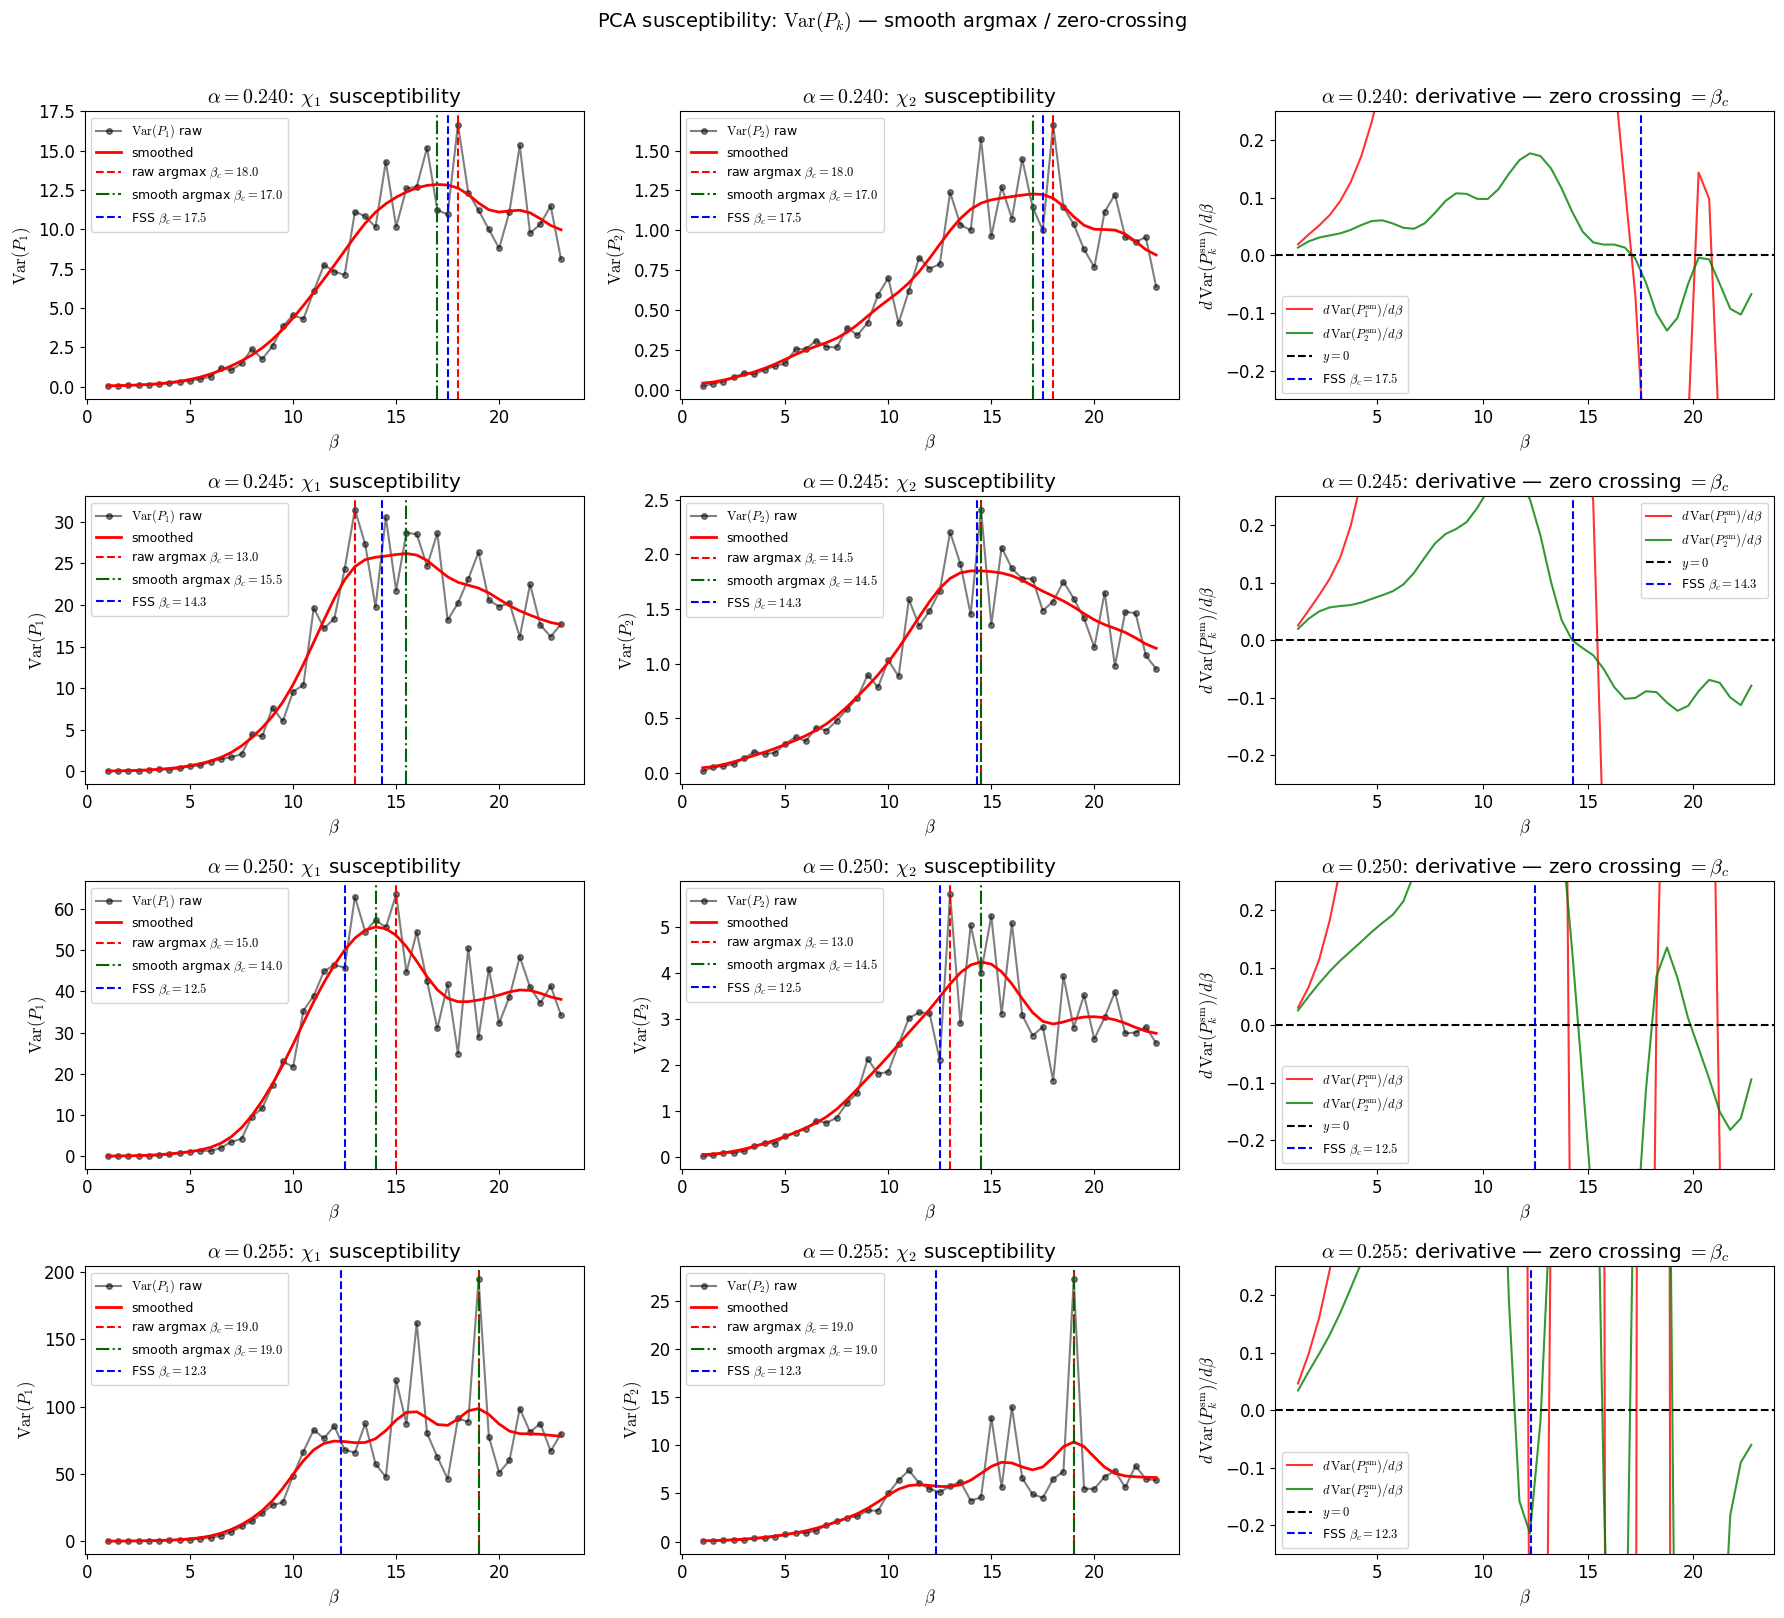

   alpha  argmax_P1    sm_P1  argmax_P2    sm_P2   km_sig km_sig_err   km_drv      FSS
----------------------------------------------------------------------------------------
   0.240     18.0     17.0     18.0     17.0     13.4      0.1     10.8     17.5
   0.245     13.0     15.5     14.5     14.5     12.8      0.1     13.8     14.3
   0.250     15.0     14.0     13.0     14.5     12.2      0.1     12.2     12.5
   0.255     19.0     19.0     19.0     19.0     11.8      0.1     11.2     12.3


In [7]:
if pca_data is not None:
    fig, axes = plt.subplots(len(ALPHAS), 3, figsize=(18, 4 * len(ALPHAS)))

    for i, alpha in enumerate(ALPHAS):
        key = f'a{alpha:.4f}'
        u_beta    = pca_data[f'{key}_u_beta']
        var_P1    = pca_data[f'{key}_var_P1']
        var_P1_sm = pca_data[f'{key}_var_P1_sm']
        var_P2    = pca_data[f'{key}_var_P2']
        var_P2_sm = pca_data[f'{key}_var_P2_sm']
        # bc layout: [argmax_P1, argmax_P2, km_sig, km_sig_err, km_deriv, best]
        bc      = pca_data[f'{key}_beta_c']
        sm1     = float(pca_data[f'{key}_sm_argmax_P1'])
        sm2     = float(pca_data[f'{key}_sm_argmax_P2'])
        d1_beta = pca_data[f'{key}_var1_deriv_beta']
        d1_vals = pca_data[f'{key}_var1_deriv_vals']
        d2_beta = pca_data[f'{key}_var2_deriv_beta']
        d2_vals = pca_data[f'{key}_var2_deriv_vals']

        # ── Col 0: Var(P1) ────────────────────────────────────────────────
        axes[i, 0].plot(u_beta, var_P1,    'ko-', ms=4, alpha=0.5, label=r'$\mathrm{Var}(P_1)$ raw')
        axes[i, 0].plot(u_beta, var_P1_sm, 'r-',  lw=2,            label=r'smoothed')
        axes[i, 0].axvline(bc[0], color='red',       ls='--', lw=1.5, label=rf'raw argmax $\beta_c={bc[0]:.1f}$')
        axes[i, 0].axvline(sm1,   color='darkgreen', ls='-.', lw=1.5, label=rf'smooth argmax $\beta_c={sm1:.1f}$')
        axes[i, 0].axvline(FSS_BETA_C[i], color='blue', ls='--', lw=1.5, label=rf'FSS $\beta_c={FSS_BETA_C[i]}$')
        axes[i, 0].set_xlabel(r'$\beta$')
        axes[i, 0].set_ylabel(r'$\mathrm{Var}(P_1)$')
        axes[i, 0].set_title(rf'$\alpha={alpha:.3f}$: $\chi_1$ susceptibility')
        axes[i, 0].legend(fontsize=9)

        # ── Col 1: Var(P2) ────────────────────────────────────────────────
        axes[i, 1].plot(u_beta, var_P2,    'ko-', ms=4, alpha=0.5, label=r'$\mathrm{Var}(P_2)$ raw')
        axes[i, 1].plot(u_beta, var_P2_sm, 'r-',  lw=2,            label=r'smoothed')
        axes[i, 1].axvline(bc[1], color='red',       ls='--', lw=1.5, label=rf'raw argmax $\beta_c={bc[1]:.1f}$')
        axes[i, 1].axvline(sm2,   color='darkgreen', ls='-.', lw=1.5, label=rf'smooth argmax $\beta_c={sm2:.1f}$')
        axes[i, 1].axvline(FSS_BETA_C[i], color='blue', ls='--', lw=1.5, label=rf'FSS $\beta_c={FSS_BETA_C[i]}$')
        axes[i, 1].set_xlabel(r'$\beta$')
        axes[i, 1].set_ylabel(r'$\mathrm{Var}(P_2)$')
        axes[i, 1].set_title(rf'$\alpha={alpha:.3f}$: $\chi_2$ susceptibility')
        axes[i, 1].legend(fontsize=9)

        # ── Col 2: d(Var_sm)/dbeta — zero crossing = beta_c ──────────────
        axes[i, 2].plot(d1_beta, d1_vals, 'r-', lw=1.5, alpha=0.8, label=r'$d\,\mathrm{Var}(P_1^\mathrm{sm})/d\beta$')
        axes[i, 2].plot(d2_beta, d2_vals, 'g-', lw=1.5, alpha=0.8, label=r'$d\,\mathrm{Var}(P_2^\mathrm{sm})/d\beta$')
        axes[i, 2].axhline(0, color='black', ls='--', lw=1.5, label=r'$y=0$')
        axes[i, 2].axvline(FSS_BETA_C[i], color='blue', ls='--', lw=1.5, label=rf'FSS $\beta_c={FSS_BETA_C[i]}$')
        axes[i, 2].set_xlabel(r'$\beta$')
        axes[i, 2].set_ylabel(r'$d\,\mathrm{Var}(P_k^\mathrm{sm})/d\beta$')
        axes[i, 2].set_title(rf'$\alpha={alpha:.3f}$: derivative — zero crossing $=\beta_c$')
        axes[i, 2].legend(fontsize=9)
        axes[i, 2].set_ylim(-0.25, 0.25)

    plt.suptitle(r'PCA susceptibility: $\mathrm{Var}(P_k)$ — smooth argmax / zero-crossing', y=1.01, fontsize=14)
    plt.tight_layout()
    save_fig('PCA', 'PCA_susceptibility_argmax.pdf')
    plt.show()

    # Summary table
    print(f'{"alpha":>8s} {"argmax_P1":>10s} {"sm_P1":>8s} {"argmax_P2":>10s} {"sm_P2":>8s} {"km_sig":>8s} {"km_sig_err":>10s} {"km_drv":>8s} {"FSS":>8s}')
    print('-' * 88)
    for i, alpha in enumerate(ALPHAS):
        key = f'a{alpha:.4f}'
        bc  = pca_data[f'{key}_beta_c']
        sm1 = float(pca_data[f'{key}_sm_argmax_P1'])
        sm2 = float(pca_data[f'{key}_sm_argmax_P2'])
        def fv(x): return f'{x:8.1f}' if not np.isnan(x) else f'{"nan":>8s}'
        print(f'{alpha:8.3f} {fv(bc[0])} {fv(sm1)} {fv(bc[1])} {fv(sm2)} {fv(bc[2])} {fv(bc[3])} {fv(bc[4])} {FSS_BETA_C[i]:8.1f}')

## Part 1B: PCA — 2D Embedding and KMeans Clustering

**How KMeans works on PCA:**
1. K-means (k=2) is applied to each configuration's $(P_1, P_2)$ coordinates.
2. The cluster with higher mean $\beta$ is labelled KVBS (ordered phase).
3. $f_{KVBS}(\beta)$ = fraction of samples at each $\beta$ in the KVBS cluster.
4. A sigmoid is fit to $f_{KVBS}$ and its derivative peak gives $\beta_c$.

**Three columns per $\alpha$** (same layout as UMAP below):
- **Left** — $P_1$ vs $P_2$ coloured by $\beta$ (the raw 2D PCA embedding).
- **Middle** — $P_1$ vs $P_2$ coloured by KMeans cluster assignment.
- **Right** — $f_{KVBS}(\beta)$ with sigmoid fit and FSS reference.

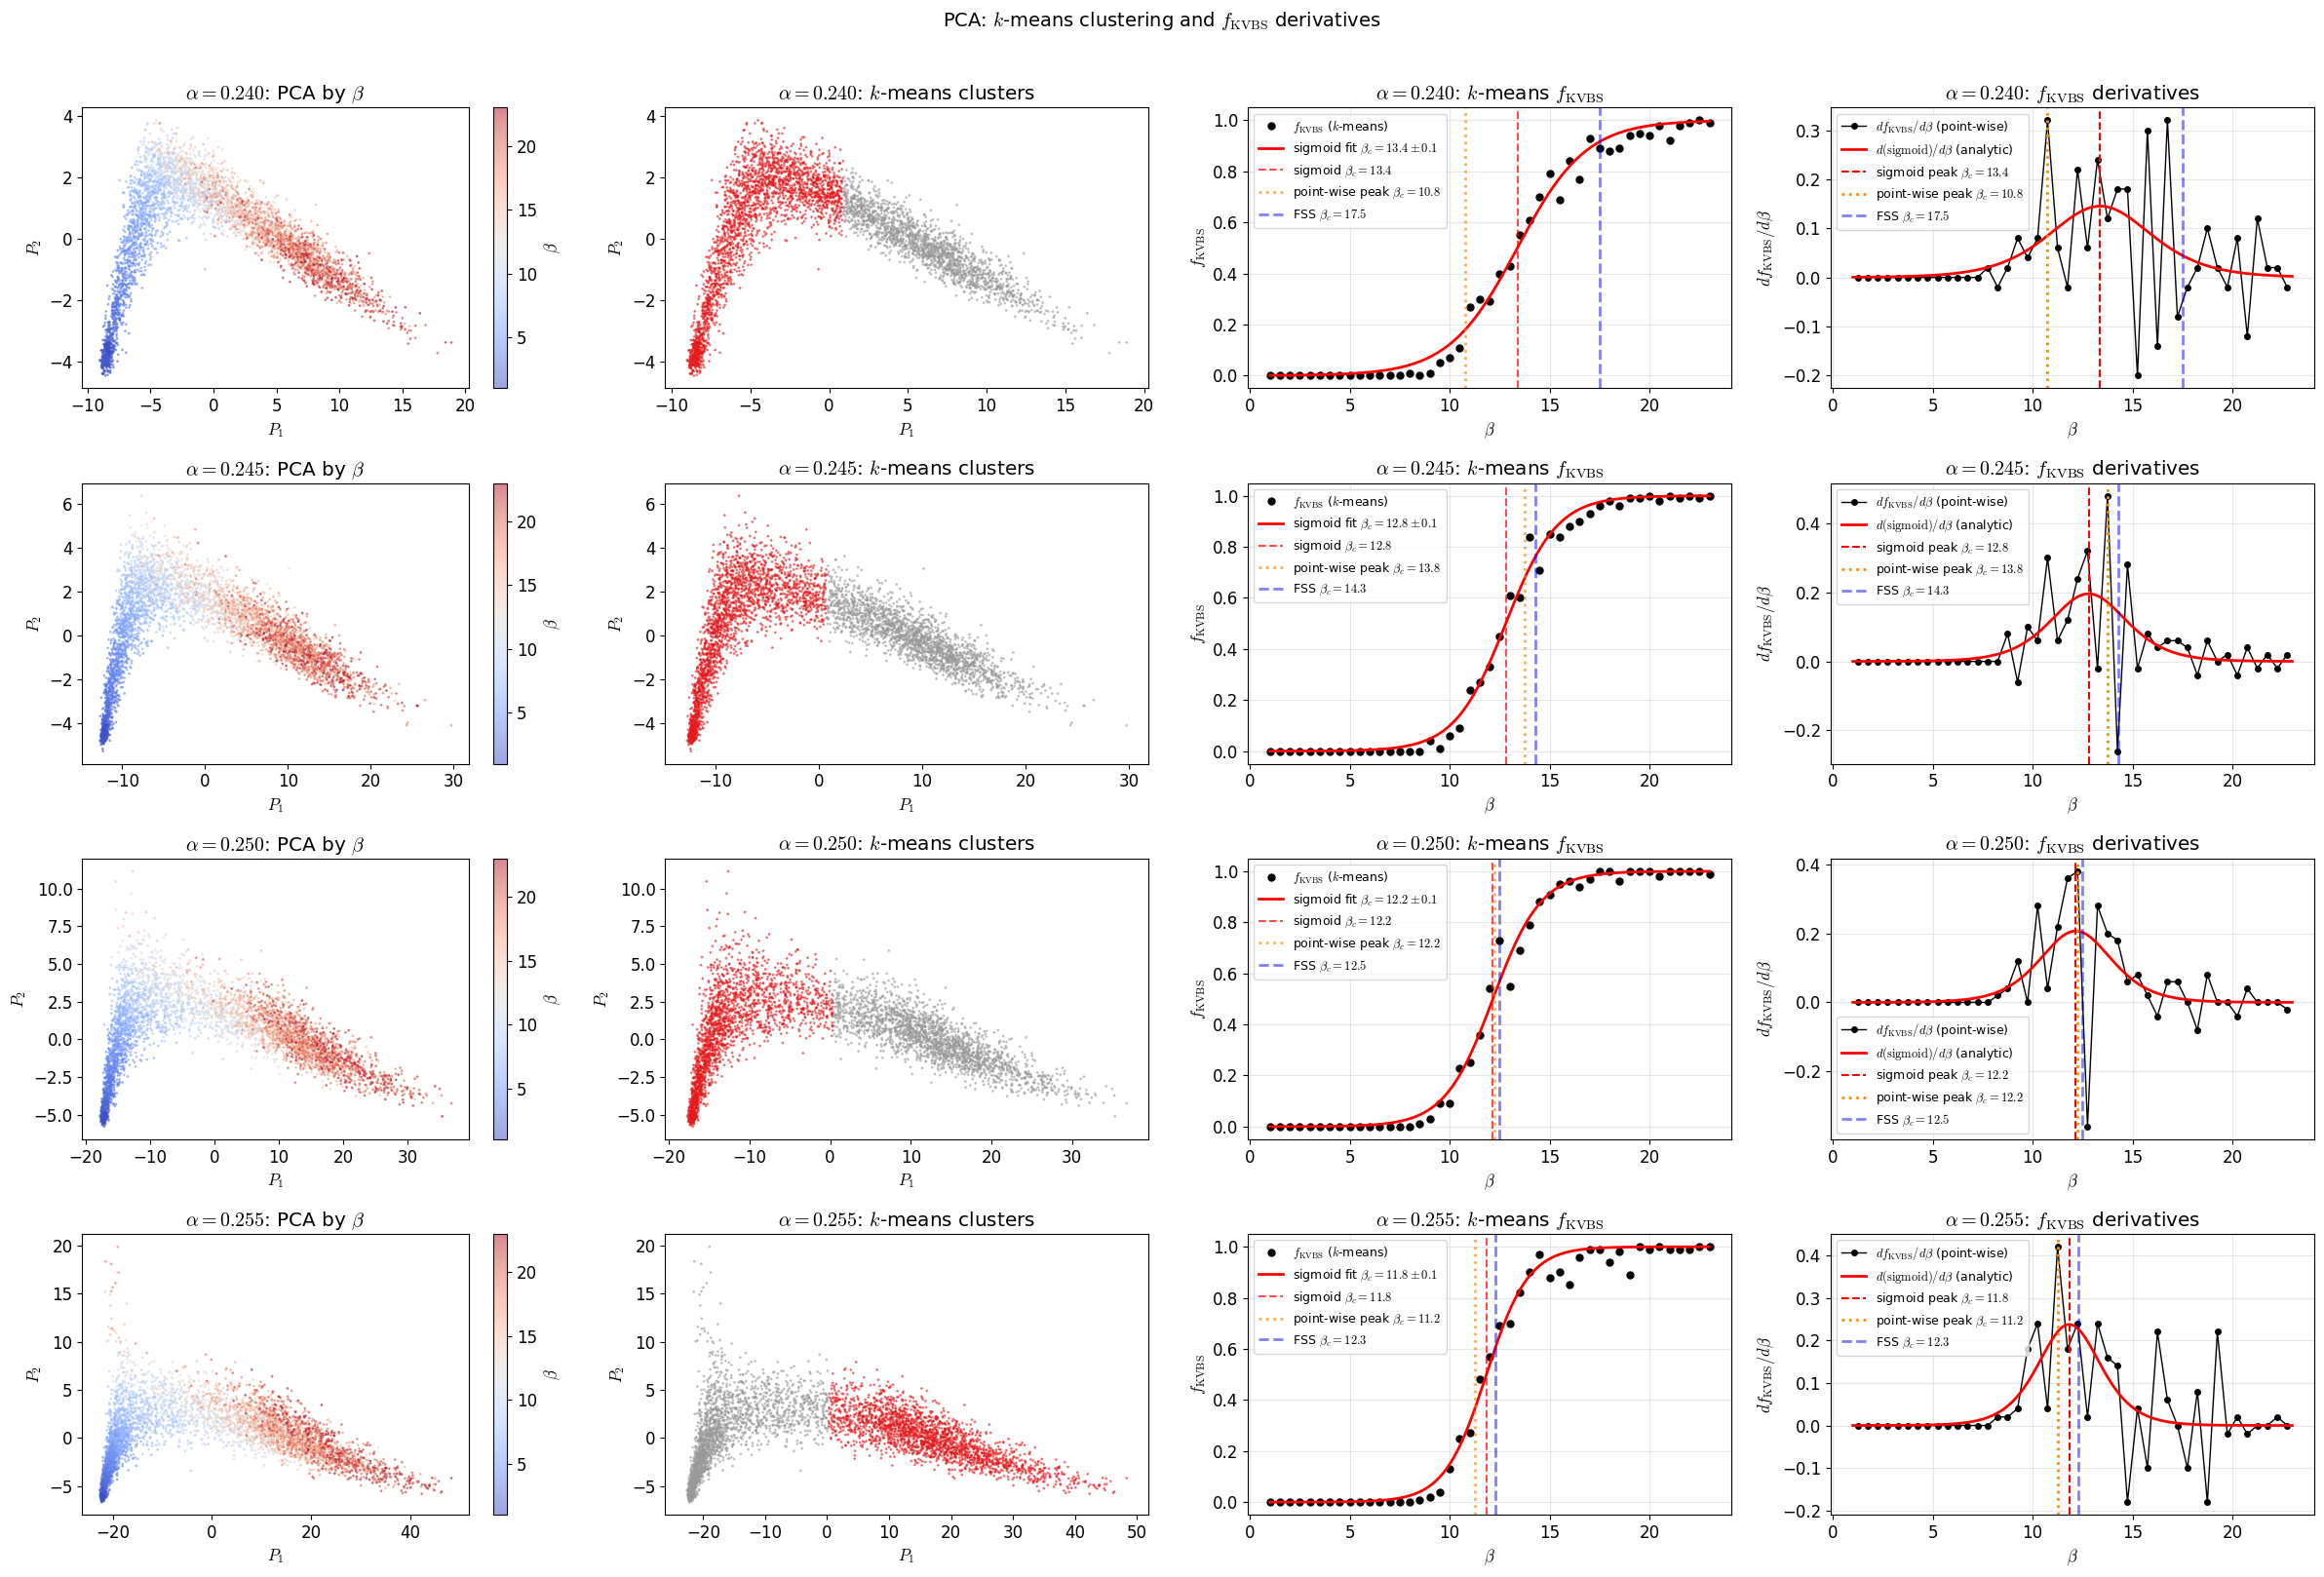

   alpha   km_sig km_sig_err  km_deriv      FSS
------------------------------------------------
   0.240     13.4      0.1     10.8     17.5
   0.245     12.8      0.1     13.8     14.3
   0.250     12.2      0.1     12.2     12.5
   0.255     11.8      0.1     11.2     12.3


In [8]:
if pca_data is not None:
    from ssh_ml_phase.pca_method import sigmoid_fit as pca_sigmoid, sigmoid_deriv as pca_sigmoid_deriv # type: ignore

    key0   = f'a{ALPHAS[0]:.4f}'
    has_km = f'{key0}_km_labels_sample' in pca_data

    if not has_km:
        print('KMeans PCA data not found — re-run: python -m ssh_ml_phase.pca_method')
    else:
        fig, axes = plt.subplots(len(ALPHAS), 4, figsize=(24, 4 * len(ALPHAS)))

        for i, alpha in enumerate(ALPHAS):
            key     = f'a{alpha:.4f}'
            P1_s    = pca_data[f'{key}_P1_sample']
            P2_s    = pca_data[f'{key}_P2_sample']
            betas_s = pca_data[f'{key}_betas_sample']
            km_s    = pca_data[f'{key}_km_labels_sample']
            u_beta  = pca_data[f'{key}_u_beta']
            f_km    = pca_data[f'{key}_f_kvbs_km']
            # bc layout: [argmax_P1, argmax_P2, km_sig, km_sig_err, km_deriv, best]
            bc        = pca_data[f'{key}_beta_c']
            beta_fine = np.linspace(u_beta[0], u_beta[-1], 500)

            # Panel 0: P1 vs P2 coloured by beta
            sc = axes[i, 0].scatter(P1_s, P2_s, c=betas_s, cmap='coolwarm', s=1, alpha=0.5)
            axes[i, 0].set_xlabel(r'$P_1$')
            axes[i, 0].set_ylabel(r'$P_2$')
            axes[i, 0].set_title(rf'$\alpha={alpha:.3f}$: PCA by $\beta$')
            plt.colorbar(sc, ax=axes[i, 0], label=r'$\beta$')

            # Panel 1: P1 vs P2 coloured by KMeans cluster
            axes[i, 1].scatter(P1_s, P2_s, c=km_s, cmap='Set1', s=1, alpha=0.5)
            axes[i, 1].set_xlabel(r'$P_1$')
            axes[i, 1].set_ylabel(r'$P_2$')
            axes[i, 1].set_title(rf'$\alpha={alpha:.3f}$: $k$-means clusters')

            # Panel 2: f_KVBS + sigmoid fit + beta_c markers
            axes[i, 2].plot(u_beta, f_km, 'ko', ms=5, label=r'$f_\mathrm{KVBS}$ ($k$-means)')
            if f'{key}_km_sig_popt' in pca_data:
                p = pca_data[f'{key}_km_sig_popt']
                axes[i, 2].plot(beta_fine, pca_sigmoid(beta_fine, *p), 'r-', lw=2,
                                label=rf'sigmoid fit $\beta_c={bc[2]:.1f}\pm{bc[3]:.1f}$')
                axes[i, 2].axvline(bc[2], color='red', lw=1.5, ls='--', alpha=0.7,
                                   label=rf'sigmoid $\beta_c={bc[2]:.1f}$')
            axes[i, 2].axvline(bc[4], color='darkorange', ls=':', lw=2, alpha=0.7,
                               label=rf'point-wise peak $\beta_c={bc[4]:.1f}$')
            axes[i, 2].axvline(FSS_BETA_C[i], color='blue', ls='--', lw=2, alpha=0.5,
                               label=rf'FSS $\beta_c={FSS_BETA_C[i]}$')
            axes[i, 2].set_xlabel(r'$\beta$')
            axes[i, 2].set_ylabel(r'$f_\mathrm{KVBS}$')
            axes[i, 2].set_ylim(-0.05, 1.05)
            axes[i, 2].set_title(rf'$\alpha={alpha:.3f}$: $k$-means $f_\mathrm{{KVBS}}$')
            axes[i, 2].legend(fontsize=9)
            axes[i, 2].grid(True, alpha=0.3)

            # Panel 3: point-wise and analytic sigmoid derivatives
            km_d_beta = pca_data[f'{key}_km_deriv_beta']
            km_d_vals = pca_data[f'{key}_km_deriv_vals']
            axes[i, 3].plot(km_d_beta, km_d_vals, 'ko-', ms=4, lw=1,
                            label=r'$df_\mathrm{KVBS}/d\beta$ (point-wise)')
            if f'{key}_km_sig_popt' in pca_data:
                p = pca_data[f'{key}_km_sig_popt']
                axes[i, 3].plot(beta_fine, pca_sigmoid_deriv(beta_fine, *p), 'r-', lw=2,
                                label=r'$d(\mathrm{sigmoid})/d\beta$ (analytic)')
                axes[i, 3].axvline(bc[2], color='red', ls='--', lw=1.5,
                                   label=rf'sigmoid peak $\beta_c={bc[2]:.1f}$')
            axes[i, 3].axvline(bc[4], color='darkorange', ls=':', lw=2,
                               label=rf'point-wise peak $\beta_c={bc[4]:.1f}$')
            axes[i, 3].axvline(FSS_BETA_C[i], color='blue', ls='--', lw=2, alpha=0.5,
                               label=rf'FSS $\beta_c={FSS_BETA_C[i]}$')
            axes[i, 3].set_xlabel(r'$\beta$')
            axes[i, 3].set_ylabel(r'$df_\mathrm{KVBS}/d\beta$')
            axes[i, 3].set_title(rf'$\alpha={alpha:.3f}$: $f_\mathrm{{KVBS}}$ derivatives')
            axes[i, 3].legend(fontsize=9)
            axes[i, 3].grid(True, alpha=0.3)

        plt.suptitle(r'PCA: $k$-means clustering and $f_\mathrm{KVBS}$ derivatives',
                     y=1.01, fontsize=14)
        plt.tight_layout()
        save_fig('PCA', 'PCA_kmeans.pdf')
        plt.show()

        # Summary
        print(f'{"alpha":>8s} {"km_sig":>8s} {"km_sig_err":>10s} {"km_deriv":>9s} {"FSS":>8s}')
        print('-' * 48)
        for i, alpha in enumerate(ALPHAS):
            bc = pca_data[f'a{alpha:.4f}_beta_c']
            def fv(x): return f'{x:8.1f}' if not np.isnan(x) else f'{"nan":>8s}'
            print(f'{alpha:8.3f} {fv(bc[2])} {fv(bc[3])} {fv(bc[4])} {FSS_BETA_C[i]:8.1f}')

---
## Part 2: UMAP + KMeans Clustering

**Why UMAP?**

UMAP is a non-linear dimensionality reduction that preserves both local and
global manifold structure better than PCA. Configurations from the same phase
cluster tightly in the 2D embedding; near the transition, points bridge the
two clusters, making the phase boundary visually and algorithmically sharp.

**KMeans on the UMAP embedding**

KMeans ($k=2$) cleanly separates the KVBS (ordered, high-$\beta$) and SM
(disordered, low-$\beta$) clusters.  The KVBS fraction

$$f_{KVBS}(\beta) = \frac{\#\{\text{samples at } \beta \text{ in KVBS cluster}\}}{\#\{\text{samples at } \beta\}}$$

transitions from 0 to 1 in a sigmoid shape through the transition.

**Two $\beta_c$ estimates from $f_{KVBS}$**

1. **Sigmoid fit** — $f(β) = 1/(1 + e^{-(β - β_c)/w})$; the midpoint $β_c$
   is the best global estimate (correct trend across $\alpha$).  The fit
   uncertainty $\sigma_{β_c}$ is shown in the legend.

2. **Point-wise derivative peak** — $\arg\max_\beta \, df_{KVBS}/d\beta$;
   sensitive to the steepest local change, complementary to the sigmoid.

**Four columns per $\alpha$:**
- **Col 1** — UMAP embedding coloured by $\beta$.
- **Col 2** — UMAP embedding coloured by KMeans cluster.
- **Col 3** — $f_{KVBS}(\beta)$ with sigmoid fit and both $\beta_c$ markers.
- **Col 4** — $df_{KVBS}/d\beta$: point-wise (dots) and analytic sigmoid
  derivative $f(1-f)/w$ (smooth curve), peaks marked.

---

/usr/local/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


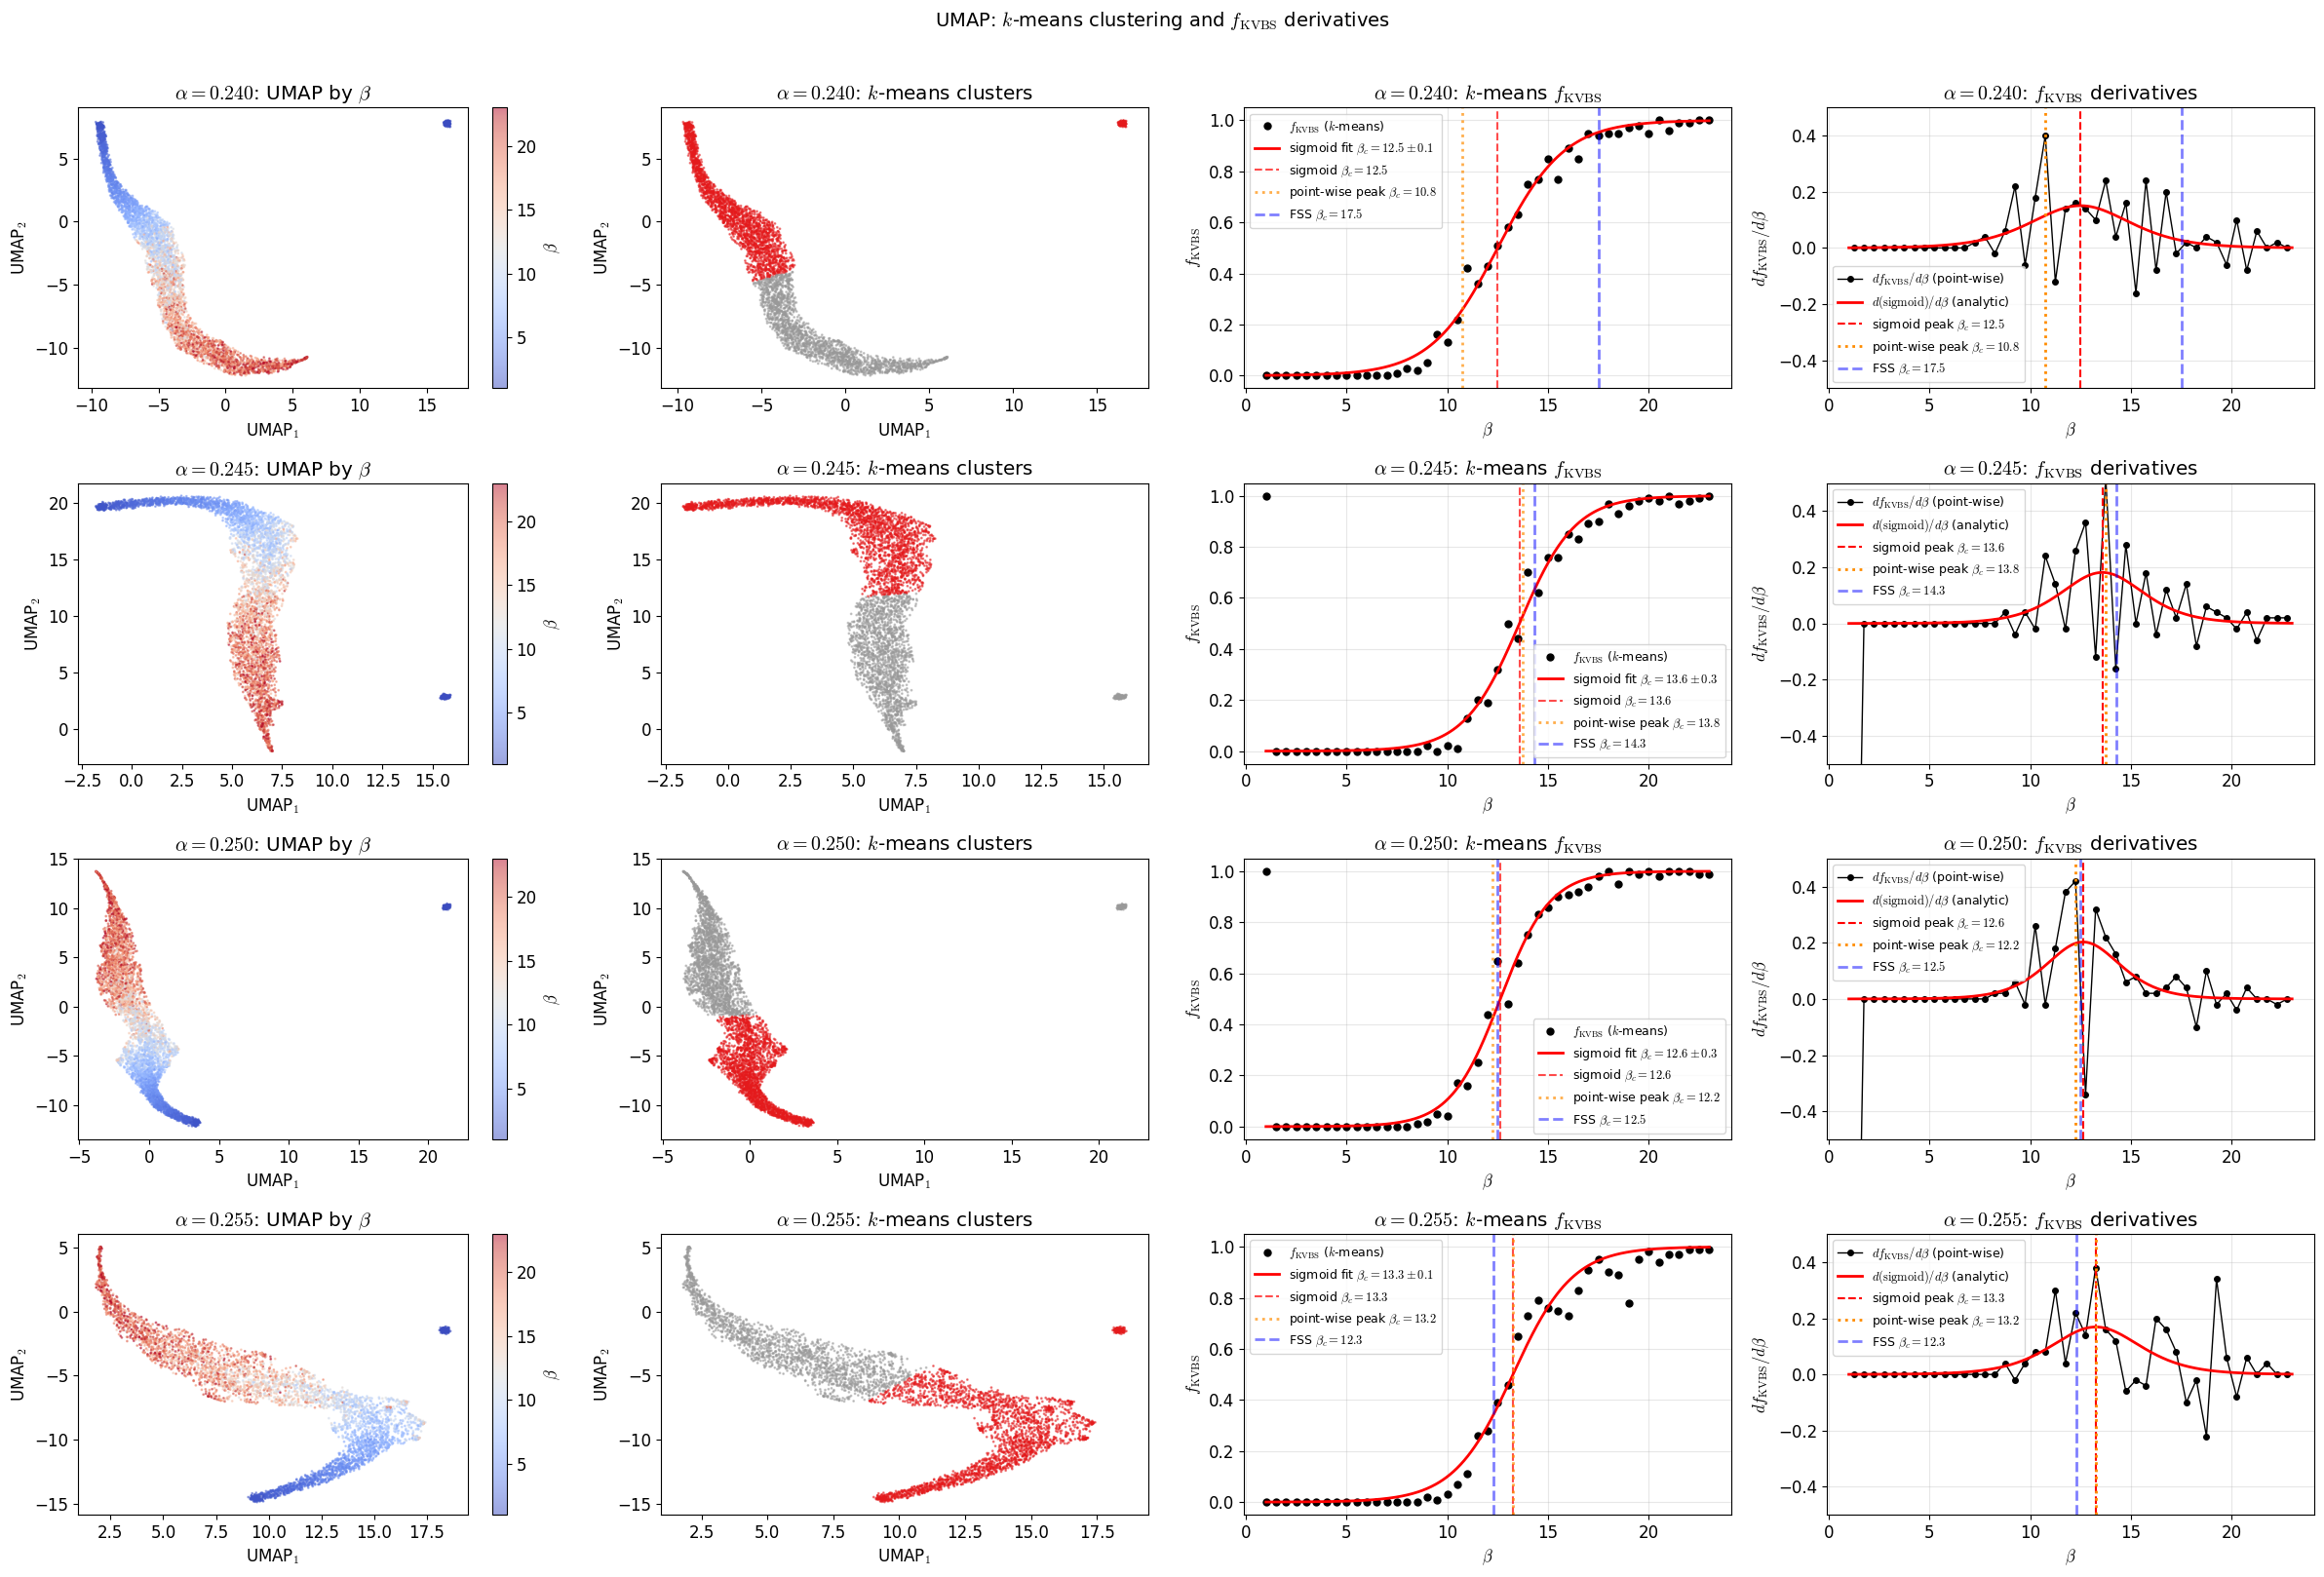

   alpha   km_sig km_sig_err  km_deriv      FSS
------------------------------------------------
   0.240     12.5      0.1     10.8     17.5
   0.245     13.6      0.3     13.8     14.3
   0.250     12.6      0.3     12.2     12.5
   0.255     13.3      0.1     13.2     12.3


In [5]:
if umap_data is not None:
    from ssh_ml_phase.umap_method import sigmoid_fit as umap_sigmoid, sigmoid_deriv as umap_sigmoid_deriv # type: ignore

    fig, axes = plt.subplots(len(ALPHAS), 4, figsize=(24, 4 * len(ALPHAS)))

    for i, alpha in enumerate(ALPHAS):
        key       = f'a{alpha:.4f}'
        emb_x     = umap_data[f'{key}_emb_x']
        emb_y     = umap_data[f'{key}_emb_y']
        emb_betas = umap_data[f'{key}_emb_betas']
        emb_km    = umap_data[f'{key}_emb_km']
        u_beta    = umap_data[f'{key}_u_beta']
        f_km      = umap_data[f'{key}_f_kvbs_km']
        # bc layout: [km_sig, km_sig_err, km_deriv, best]
        bc        = umap_data[f'{key}_beta_c']
        beta_fine = np.linspace(u_beta[0], u_beta[-1], 500)

        # Panel 0: UMAP coloured by beta
        sc = axes[i, 0].scatter(emb_x, emb_y, c=emb_betas, cmap='coolwarm', s=1, alpha=0.5)
        axes[i, 0].set_xlabel(r'UMAP$_1$')
        axes[i, 0].set_ylabel(r'UMAP$_2$')
        axes[i, 0].set_title(rf'$\alpha={alpha:.3f}$: UMAP by $\beta$')
        plt.colorbar(sc, ax=axes[i, 0], label=r'$\beta$')

        # Panel 1: UMAP coloured by KMeans cluster
        axes[i, 1].scatter(emb_x, emb_y, c=emb_km, cmap='Set1', s=1, alpha=0.5)
        axes[i, 1].set_xlabel(r'UMAP$_1$')
        axes[i, 1].set_ylabel(r'UMAP$_2$')
        axes[i, 1].set_title(rf'$\alpha={alpha:.3f}$: $k$-means clusters')

        # Panel 2: f_KVBS + sigmoid fit + beta_c markers
        axes[i, 2].plot(u_beta, f_km, 'ko', ms=5, label=r'$f_\mathrm{KVBS}$ ($k$-means)')
        if f'{key}_km_sig_popt' in umap_data:
            p = umap_data[f'{key}_km_sig_popt']
            axes[i, 2].plot(beta_fine, umap_sigmoid(beta_fine, *p), 'r-', lw=2,
                            label=rf'sigmoid fit $\beta_c={bc[0]:.1f}\pm{bc[1]:.1f}$')
            axes[i, 2].axvline(bc[0], color='red', lw=1.5, ls='--', alpha=0.7,
                               label=rf'sigmoid $\beta_c={bc[0]:.1f}$')
        axes[i, 2].axvline(bc[2], color='darkorange', ls=':', lw=2, alpha=0.7,
                           label=rf'point-wise peak $\beta_c={bc[2]:.1f}$')
        axes[i, 2].axvline(FSS_BETA_C[i], color='blue', ls='--', lw=2, alpha=0.5,
                           label=rf'FSS $\beta_c={FSS_BETA_C[i]}$')
        axes[i, 2].set_xlabel(r'$\beta$')
        axes[i, 2].set_ylabel(r'$f_\mathrm{KVBS}$')
        axes[i, 2].set_ylim(-0.05, 1.05)
        axes[i, 2].set_title(rf'$\alpha={alpha:.3f}$: $k$-means $f_\mathrm{{KVBS}}$')
        axes[i, 2].legend(fontsize=9)
        axes[i, 2].grid(True, alpha=0.3)

        # Panel 3: point-wise and analytic sigmoid derivatives
        km_d_beta = umap_data[f'{key}_km_deriv_beta']
        km_d_vals = umap_data[f'{key}_km_deriv_vals']
        axes[i, 3].plot(km_d_beta, km_d_vals, 'ko-', ms=4, lw=1,
                        label=r'$df_\mathrm{KVBS}/d\beta$ (point-wise)')
        if f'{key}_km_sig_popt' in umap_data:
            p = umap_data[f'{key}_km_sig_popt']
            axes[i, 3].plot(beta_fine, umap_sigmoid_deriv(beta_fine, *p), 'r-', lw=2,
                            label=r'$d(\mathrm{sigmoid})/d\beta$ (analytic)')
            axes[i, 3].axvline(bc[0], color='red', ls='--', lw=1.5,
                               label=rf'sigmoid peak $\beta_c={bc[0]:.1f}$')
        axes[i, 3].axvline(bc[2], color='darkorange', ls=':', lw=2,
                           label=rf'point-wise peak $\beta_c={bc[2]:.1f}$')
        axes[i, 3].axvline(FSS_BETA_C[i], color='blue', ls='--', lw=2, alpha=0.5,
                           label=rf'FSS $\beta_c={FSS_BETA_C[i]}$')
        axes[i, 3].set_xlabel(r'$\beta$')
        axes[i, 3].set_ylabel(r'$df_\mathrm{KVBS}/d\beta$')
        axes[i, 3].set_title(rf'$\alpha={alpha:.3f}$: $f_\mathrm{{KVBS}}$ derivatives')
        axes[i, 3].legend(fontsize=9)
        axes[i, 3].grid(True, alpha=0.3)
        axes[i, 3].set_ylim(-0.5, 0.5)

    plt.suptitle(r'UMAP: $k$-means clustering and $f_\mathrm{KVBS}$ derivatives', y=1.01, fontsize=14)
    plt.tight_layout()
    save_fig('UMAP', 'UMAP_beta_c.pdf')
    plt.show()

    # Summary table
    print(f'{"alpha":>8s} {"km_sig":>8s} {"km_sig_err":>10s} {"km_deriv":>9s} {"FSS":>8s}')
    print('-' * 48)
    for i, alpha in enumerate(ALPHAS):
        bc = umap_data[f'a{alpha:.4f}_beta_c']
        def fv(x): return f'{x:8.1f}' if not np.isnan(x) else f'{"nan":>8s}'
        print(f'{alpha:8.3f} {fv(bc[0])} {fv(bc[1])} {fv(bc[2])} {FSS_BETA_C[i]:8.1f}')

---
## Part 3: Assaad (Greitemann-Iqbal) Method
---

In [ ]:
if assaad_data is not None:
    nskip_values = [4, 6, 8]
    fig, axes = plt.subplots(1, len(ALPHAS), figsize=(5 * len(ALPHAS), 4))

    for i, alpha in enumerate(ALPHAS):
        for nskip in nskip_values:
            akey = f'a{alpha:.4f}_ns{nskip}'
            if f'{akey}_betas' not in assaad_data:
                continue
            betas = assaad_data[f'{akey}_betas']
            accs  = assaad_data[f'{akey}_accs']
            bc    = assaad_data[f'{akey}_beta_c'][0]
            axes[i].plot(betas, accs, 'o-', ms=3,
                         label=rf'$n_{{\mathrm{{skip}}}}={nskip}$,  $\beta_c={bc:.1f}$')

        axes[i].axvline(FSS_BETA_C[i], color='black', ls='--', lw=2,
                        label=rf'FSS $\beta_c={FSS_BETA_C[i]}$')
        axes[i].set_xlabel(r'guessed $\beta_c$')
        axes[i].set_ylabel(r'test accuracy')
        axes[i].set_title(rf'$\alpha={alpha:.3f}$')
        axes[i].legend(fontsize=7)
        axes[i].grid(True, alpha=0.3)

    plt.suptitle(r'Assaad--GI method: test accuracy vs guessed $\beta_c$', y=1.02)
    plt.tight_layout()
    save_fig('Part3_assaad_accuracy.pdf')
    plt.show()

    print(f'{"alpha":>8s}', ''.join(f'{"ns="+str(n):>10s}' for n in nskip_values), f'{"FSS":>8s}')
    print('-' * 50)
    for i, alpha in enumerate(ALPHAS):
        vals = ''
        for nskip in nskip_values:
            akey = f'a{alpha:.4f}_ns{nskip}'
            if f'{akey}_beta_c' in assaad_data:
                vals += f'{assaad_data[f"{akey}_beta_c"][0]:10.1f}'
            else:
                vals += f'{"--":>10s}'
        print(f'{alpha:8.3f}{vals}{FSS_BETA_C[i]:8.1f}')

---
## Part 4: Autoencoder Anomaly Detection

The autoencoder is trained on **all data** with a tight bottleneck (latent_dim=2).

### Why the AE latent space separates at β ≈ 12 (not β_c)

The AE bottleneck forces the network to learn the **most dominant mode of
variation** in the bond-bond correlation data.  For this data, that dominant
mode is the same momentum-space V-shaped crossover at β ≈ 12 that dominates
PCA — it is present for **all** α values and is unrelated to the true phase
transition.  As a result:
- The latent coordinate $z_0$ tracks the V-shape, separating samples into
  β < 12 and β > 12 clusters for **every** α.
- KMeans on the latent space cuts the space at β ≈ 12, so $\beta_c^{KM} ≈ 12$
  regardless of the true FSS value.

### Why mean_error is monotone — and its derivative peaks at β_c

Trained on all data, the AE must compress every configuration through a 2D
bottleneck.  Disordered (low-β) configurations are structurally diverse and
hard to compress → **large** reconstruction error.  Ordered (high-β) VBS
configurations are repetitive → **small** error.  So $\langle\text{error}\rangle(\beta)$
is a **monotonically decreasing** function — it acts like an order parameter,
not a susceptibility.  Its **derivative** $d\langle\text{error}\rangle/d\beta$
peaks where the descent is steepest, which is the inflection point = β_c.

The first 2–3 β points (β = 1–2) often show spurious large finite differences
because at very low temperature the configurations change very little from step
to step, but small absolute changes produce large *relative* differences in the
raw noisy error values.

**Three columns per α (below):**
- **Left** — Mean reconstruction error (monotone ↓, inflection ≈ β_c).
- **Middle** — $|d\langle\text{error}\rangle/d\beta|$ raw.  Peak ≈ β_c when the first noisy points are ignored.
- **Right** — $\langle|z_0|\rangle$ learned order parameter and Var($z_0$).

---

In [ ]:
if ae_data is not None:
    from ssh_ml_phase.autoencoder import decreasing_sigmoid  # type: ignore
    from scipy.optimize import curve_fit as _cf

    fig, axes = plt.subplots(len(ALPHAS), 3, figsize=(20, 4 * len(ALPHAS)))
    if len(ALPHAS) == 1:
        axes = axes[np.newaxis, :]

    for i, alpha in enumerate(ALPHAS):
        key        = f'a{alpha:.4f}'
        if f'{key}_u_beta' not in ae_data:
            continue
        u_beta     = ae_data[f'{key}_u_beta']
        mean_error = ae_data[f'{key}_mean_error']
        bc         = ae_data[f'{key}_beta_c']
        bc_err_sig = float(bc[-2]) if len(bc) >= 7 else np.nan
        bc_best    = float(bc[-1])

        try:
            A0, B0 = float(mean_error.max() - mean_error.min()), float(mean_error.min())
            popt_es, _ = _cf(
                decreasing_sigmoid, u_beta, mean_error,
                p0=[FSS_BETA_C[i], 3.0, A0, B0],
                bounds=([u_beta[3], 0.5, 0.0, -np.inf],
                        [u_beta[-3], 20.0, np.inf, np.inf]),
                maxfev=10000,
            )
            bc_sig_nb = float(popt_es[0])
        except Exception:
            popt_es   = None
            bc_sig_nb = np.nan

        beta_fine = np.linspace(u_beta[0], u_beta[-1], 500)

        # Col 0: mean reconstruction error + sigmoid fit
        axes[i, 0].plot(u_beta, mean_error, 'ko-', ms=4, label=r'$\langle\mathrm{error}\rangle$')
        if popt_es is not None:
            axes[i, 0].plot(beta_fine, decreasing_sigmoid(beta_fine, *popt_es), 'r-', lw=2,
                            label=rf'sigmoid fit $\beta_c={bc_sig_nb:.1f}$')
        axes[i, 0].axvline(bc_sig_nb if not np.isnan(bc_sig_nb) else bc_best,
                           color='red', ls='--', lw=1.5)
        axes[i, 0].axvline(FSS_BETA_C[i], color='blue', ls='--', lw=2,
                           label=rf'FSS $\beta_c={FSS_BETA_C[i]}$')
        axes[i, 0].set_xlabel(r'$\beta$')
        axes[i, 0].set_ylabel(r'$\langle\mathrm{error}\rangle$')
        axes[i, 0].set_title(rf'$\alpha={alpha:.3f}$: mean error (monotone $\downarrow$)')
        axes[i, 0].legend(fontsize=9)
        axes[i, 0].grid(True, alpha=0.3)

        # Col 1: |d(error)/dbeta|
        if f'{key}_deriv_beta' in ae_data:
            d_beta = ae_data[f'{key}_deriv_beta']
            d_vals = ae_data[f'{key}_deriv_vals']
            axes[i, 1].plot(d_beta, np.abs(d_vals), 'ko-', ms=4,
                            label=r'$|d\langle\mathrm{error}\rangle/d\beta|$')
            axes[i, 1].axvline(float(bc[0]), color='black', ls=':', lw=1.5,
                               label=rf'deriv peak $\beta_c={bc[0]:.1f}$')
            axes[i, 1].axvline(bc_sig_nb if not np.isnan(bc_sig_nb) else bc_best,
                               color='red', ls='--', lw=1.5,
                               label=rf'sigmoid $\beta_c={bc_sig_nb:.1f}$')
            axes[i, 1].axvline(FSS_BETA_C[i], color='blue', ls='--', lw=2,
                               label=rf'FSS $\beta_c={FSS_BETA_C[i]}$')
            axes[i, 1].set_xlabel(r'$\beta$')
            axes[i, 1].set_ylabel(r'$|d\langle\mathrm{error}\rangle/d\beta|$')
            axes[i, 1].set_title(rf'$\alpha={alpha:.3f}$: error derivative (raw)')
            axes[i, 1].legend(fontsize=8)
            axes[i, 1].grid(True, alpha=0.3)

        # Col 2: <|z0|> learned order parameter + Var(z0)
        if f'{key}_mean_abs_z0' in ae_data:
            mz0 = ae_data[f'{key}_mean_abs_z0']
            axes[i, 2].plot(u_beta, mz0, 'g^-', ms=4, label=r'$\langle|z_0|\rangle$')
        if f'{key}_var_z0' in ae_data:
            var_z0 = ae_data[f'{key}_var_z0']
            ax2 = axes[i, 2].twinx()
            ax2.plot(u_beta, var_z0, 'r--', ms=3, alpha=0.6, label=r'$\mathrm{Var}(z_0)$')
            ax2.set_ylabel(r'$\mathrm{Var}(z_0)$', color='red')
            ax2.tick_params(axis='y', labelcolor='red')
            ax2.legend(fontsize=7, loc='upper left')
        axes[i, 2].axvline(bc_best, color='orange', ls='-', lw=2, alpha=0.8,
                           label=rf'best $\beta_c={bc_best:.1f}$')
        axes[i, 2].axvline(FSS_BETA_C[i], color='blue', ls='--', lw=2,
                           label=rf'FSS $\beta_c={FSS_BETA_C[i]}$')
        axes[i, 2].set_xlabel(r'$\beta$')
        axes[i, 2].set_ylabel(r'$\langle|z_0|\rangle$')
        axes[i, 2].set_title(rf'$\alpha={alpha:.3f}$: learned order parameter')
        axes[i, 2].legend(fontsize=8)
        axes[i, 2].grid(True, alpha=0.3)

    plt.tight_layout()
    save_fig('Part4_autoencoder.pdf')
    plt.show()

    print(f'{"alpha":>8s} {"deriv":>8s} {"z0_drv":>8s} {"err_sig":>8s} {"best":>8s} {"FSS":>8s}')
    print('-' * 55)
    for i, alpha in enumerate(ALPHAS):
        key = f'a{alpha:.4f}'
        if f'{key}_beta_c' in ae_data:
            bc = ae_data[f'{key}_beta_c']
            es = float(bc[-2]) if len(bc) >= 7 else float('nan')
            print(f'{alpha:8.3f} {bc[0]:8.1f} {bc[1]:8.1f} {es:8.1f} {float(bc[-1]):8.1f} {FSS_BETA_C[i]:8.1f}')

In [ ]:
# Latent space scatter: colored by beta (top) and KMeans cluster (bottom)
if ae_data is not None:
    key0 = f'a{ALPHAS[0]:.4f}'
    has_lat_km = f'{key0}_lat_km_sample' in ae_data

    n_rows = 2 if has_lat_km else 1
    fig, axes = plt.subplots(n_rows, len(ALPHAS), figsize=(5 * len(ALPHAS), 4 * n_rows))
    if len(ALPHAS) == 1:
        axes = axes[:, np.newaxis]
    if n_rows == 1:
        axes = axes[np.newaxis, :]

    for i, alpha in enumerate(ALPHAS):
        key = f'a{alpha:.4f}'
        if f'{key}_z0_sample' not in ae_data:
            continue
        z0 = ae_data[f'{key}_z0_sample']
        z1 = ae_data[f'{key}_z1_sample']
        betas_s = ae_data[f'{key}_betas_sample']

        # Row 0: colored by beta
        sc = axes[0, i].scatter(z0, z1, c=betas_s, cmap='coolwarm', s=1, alpha=0.5)
        axes[0, i].set_xlabel(r'$z_0$')
        axes[0, i].set_ylabel(r'$z_1$')
        axes[0, i].set_title(rf'$\alpha={alpha:.3f}$: by $\beta$')
        plt.colorbar(sc, ax=axes[0, i], label=r'$\beta$')

        # Row 1: colored by KMeans cluster (if available)
        if has_lat_km:
            km_s = ae_data[f'{key}_lat_km_sample']
            axes[1, i].scatter(z0, z1, c=km_s, cmap='Set1', s=1, alpha=0.5)
            axes[1, i].set_xlabel(r'$z_0$')
            axes[1, i].set_ylabel(r'$z_1$')
            axes[1, i].set_title(rf'$\alpha={alpha:.3f}$: $k$-means clusters')

    plt.suptitle(r'Autoencoder latent space ($z_0$ vs $z_1$)', y=1.01, fontsize=14)
    plt.tight_layout()
    save_fig('Part4_latent_scatter.pdf')
    plt.show()

## Part 4B: Autoencoder — KMeans Clustering in Latent Space

KMeans (k=2) is applied to each configuration's $(z_0, z_1)$ latent coordinates.
The cluster with higher mean $\beta$ is labelled KVBS; $f_{KVBS}(\beta)$ gives a
sigmoid whose midpoint is $\beta_c$.

**Note:** because the AE latent space separates at β ≈ 12 (the bond-bond V-shape
crossover) rather than at the true β_c, the KMeans clusters and their sigmoid
midpoints are biased toward β ≈ 12 for all α.

In [ ]:
if ae_data is not None:
    from ssh_ml_phase.autoencoder import sigmoid_fit as ae_sigmoid  # type: ignore

    key0 = f'a{ALPHAS[0]:.4f}'
    has_lat_km = f'{key0}_f_kvbs_lat' in ae_data and f'{key0}_lat_km_sample' in ae_data

    if not has_lat_km:
        print('Latent KMeans data not found — re-run: python -m ssh_ml_phase.autoencoder')
    else:
        # 2 columns per alpha: left = z0 vs z1 KMeans scatter, right = f_KVBS curve
        fig, axes = plt.subplots(len(ALPHAS), 2, figsize=(12, 4 * len(ALPHAS)))
        if len(ALPHAS) == 1:
            axes = axes[np.newaxis, :]

        for i, alpha in enumerate(ALPHAS):
            key = f'a{alpha:.4f}'
            if f'{key}_f_kvbs_lat' not in ae_data:
                continue

            u_beta  = ae_data[f'{key}_u_beta']
            f_lat   = ae_data[f'{key}_f_kvbs_lat']
            bc      = ae_data[f'{key}_beta_c']
            z0_s    = ae_data[f'{key}_z0_sample']
            z1_s    = ae_data[f'{key}_z1_sample']
            km_s    = ae_data[f'{key}_lat_km_sample']

            # Col 0: z0 vs z1 coloured by KMeans cluster
            axes[i, 0].scatter(z0_s, z1_s, c=km_s, cmap='Set1', s=1, alpha=0.5)
            axes[i, 0].set_xlabel(r'$z_0$')
            axes[i, 0].set_ylabel(r'$z_1$')
            axes[i, 0].set_title(rf'$\alpha={alpha:.3f}$: latent $k$-means clusters')

            # Col 1: f_KVBS(beta) + sigmoid fit + derivative peak
            beta_fine = np.linspace(u_beta[0], u_beta[-1], 500)
            axes[i, 1].plot(u_beta, f_lat, 'ko', ms=5, label=r'$f_\mathrm{KVBS}$')
            if f'{key}_sigmoid_lat' in ae_data:
                p = ae_data[f'{key}_sigmoid_lat']
                km_bc = float(bc[3]) if len(bc) >= 5 else np.nan
                axes[i, 1].plot(beta_fine, ae_sigmoid(beta_fine, *p), 'r-', lw=2,
                                label=rf'sigmoid $\beta_c={km_bc:.1f}$')
            km_deriv = float(bc[4]) if len(bc) >= 5 else np.nan
            axes[i, 1].axvline(km_deriv, color='darkorange', ls=':', lw=2,
                               label=rf'deriv peak $\beta_c={km_deriv:.1f}$')
            axes[i, 1].axvline(FSS_BETA_C[i], color='blue', ls='--', lw=2,
                               label=rf'FSS $\beta_c={FSS_BETA_C[i]}$')
            axes[i, 1].set_xlabel(r'$\beta$')
            axes[i, 1].set_ylabel(r'$f_\mathrm{KVBS}$')
            axes[i, 1].set_ylim(-0.05, 1.05)
            axes[i, 1].set_title(rf'$\alpha={alpha:.3f}$: $f_\mathrm{{KVBS}}(\beta)$')
            axes[i, 1].legend(fontsize=9)
            axes[i, 1].grid(True, alpha=0.3)

        plt.suptitle(r'AE latent: $k$-means clusters and $f_\mathrm{KVBS}(\beta)$',
                     y=1.01, fontsize=14)
        plt.tight_layout()
        save_fig('Part4_latent_kmeans.pdf')
        plt.show()

        print(f'{"alpha":>8s} {"lat_km_sig":>11s} {"lat_km_drv":>11s} {"FSS":>8s}')
        print('-' * 42)
        for i, alpha in enumerate(ALPHAS):
            key = f'a{alpha:.4f}'
            if f'{key}_beta_c' in ae_data:
                bc = ae_data[f'{key}_beta_c']
                if len(bc) >= 5:
                    print(f'{alpha:8.3f} {float(bc[3]):11.1f} {float(bc[4]):11.1f} {FSS_BETA_C[i]:8.1f}')

---
## Final Summary: All Methods vs FSS
---

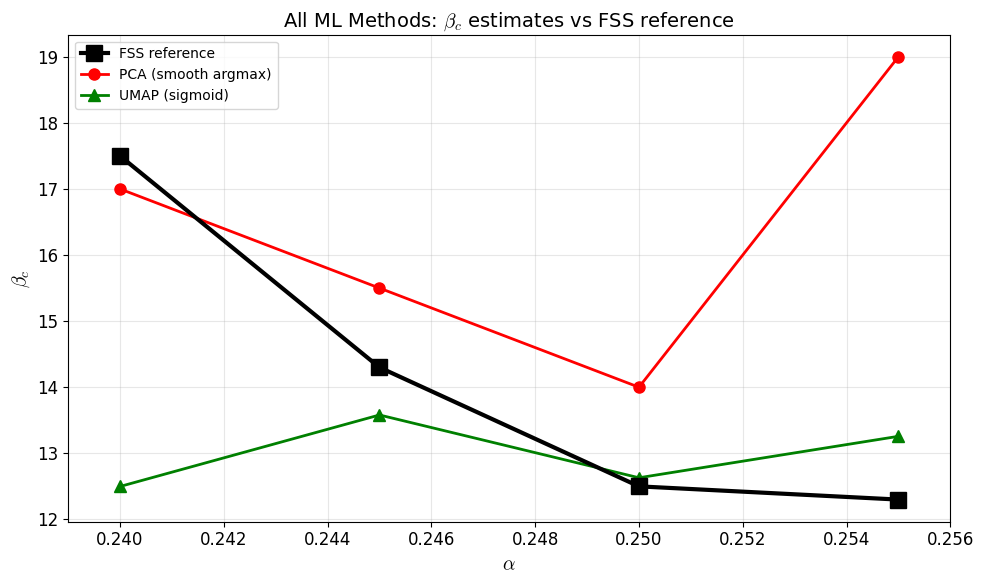


FINAL SUMMARY: beta_c estimates from all methods
   alpha      PCA     UMAP      FSS
----------------------------------------------------------------------
   0.240     17.0     12.5     17.5
   0.245     15.5     13.6     14.3
   0.250     14.0     12.6     12.5
   0.255     19.0     13.3     12.3


In [9]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(FSS_ALPHA, FSS_BETA_C, 'ks-', ms=12, lw=3, label='FSS reference', zorder=10)

# PCA best = sm_argmax_P1 (bc[-1])
if pca_data is not None:
    pca_best = [float(pca_data[f'a{a:.4f}_beta_c'][-1]) for a in ALPHAS]
    ax.plot(ALPHAS, pca_best, 'ro-', ms=8, lw=2, label='PCA (smooth argmax)')

# UMAP best = km_sig (sigmoid peak, bc[-1])
if umap_data is not None:
    umap_best = [float(umap_data[f'a{a:.4f}_beta_c'][-1]) for a in ALPHAS]
    ax.plot(ALPHAS, umap_best, 'g^-', ms=8, lw=2, label='UMAP (sigmoid)')

# Assaad (nskip=6)
if assaad_data is not None:
    assaad_vals = []
    for a in ALPHAS:
        akey = f'a{a:.4f}_ns6'
        if f'{akey}_beta_c' in assaad_data:
            assaad_vals.append(assaad_data[f'{akey}_beta_c'][0])
        else:
            assaad_vals.append(np.nan)
    ax.plot(ALPHAS, assaad_vals, 'bD-', ms=8, lw=2, label='Assaad GI (nskip=6)')

# Autoencoder best (bc[-1])
if ae_data is not None:
    ae_best = []
    for a in ALPHAS:
        key = f'a{a:.4f}'
        if f'{key}_beta_c' in ae_data:
            ae_best.append(float(ae_data[f'{key}_beta_c'][-1]))
        else:
            ae_best.append(np.nan)
    ax.plot(ALPHAS, ae_best, 'mv-', ms=8, lw=2, label='AE (deriv avg)')

ax.set_xlabel('$\\alpha$', fontsize=14)
ax.set_ylabel('$\\beta_c$', fontsize=14)
ax.set_xlim(0.239, 0.256)
ax.set_title('All ML Methods: $\\beta_c$ estimates vs FSS reference', fontsize=14)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
save_fig('Final_summary_all_methods.pdf')
plt.show()

# Final table
print('\n' + '='*70)
print('FINAL SUMMARY: beta_c estimates from all methods')
print('='*70)
header = f'{"alpha":>8s}'
if pca_data:  header += f' {"PCA":>8s}'
if umap_data: header += f' {"UMAP":>8s}'
if assaad_data: header += f' {"Assaad":>8s}'
if ae_data:   header += f' {"AE":>8s}'
header += f' {"FSS":>8s}'
print(header)
print('-'*70)
for i, alpha in enumerate(ALPHAS):
    row = f'{alpha:8.3f}'
    if pca_data:    row += f' {pca_best[i]:8.1f}'
    if umap_data:   row += f' {umap_best[i]:8.1f}'
    if assaad_data: row += f' {assaad_vals[i]:8.1f}'
    if ae_data:     row += f' {ae_best[i]:8.1f}'
    row += f' {FSS_BETA_C[i]:8.1f}'
    print(row)
print('='*70)